Uykuya dalma süresi ve öncesi ekran kullanımı 
-

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
df = pd.read_csv('bedtime_screentime_sleep_debt.csv')
df

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,USR-08496,61,Female,Remote Tech,Night Owl,18,Streaming (Netflix/Hulu),61,1,60,74,21.0,5.57,26.5,18.1,3,3.2,Moderate Debt
8496,USR-08497,64,Male,Student,Night Owl,138,TikTok / Reels,58,1,0,58,84.3,3.99,20.4,19.4,7,10.0,Severe Sleep Debt
8497,USR-08498,34,Male,Corporate 9-to-5,Intermediate,56,Streaming (Netflix/Hulu),56,0,94,33,40.6,7.58,17.4,20.7,2,3.7,Mild Deficit
8498,USR-08499,23,Male,Healthcare / Shift Worker,Night Owl,165,TikTok / Reels,72,0,0,52,123.3,3.20,14.2,15.8,7,10.0,Severe Sleep Debt


### Questions I Wanted to Explore

- Which apps are used the most before going to sleep?
- Which gender has higher screen time?
- Is there a relationship between age and screen time?
- Is there a relationship between screen brightness and age?
- Does drinking caffeine after 5 PM make it harder to fall asleep?
- Does caffeine affect REM sleep or deep sleep?
- Does physical activity make it easier to fall asleep?
- Does having less deep sleep affect the next day's fatigue score?
- Is there a relationship between alarm snoozing and deep/REM sleep?
- Does spending time on the phone affect sleep latency?
- Does the amount of REM and deep sleep differ by gender?
- How does alarm snoozing affect the next day?
- Is there a relationship between occupation type and screen time?
- How do sleep duration and sleep patterns differ between chronotypes?
- Does using a blue-light filter affect REM sleep?
- Does higher screen brightness affect sleep latency?
- Which app do people spend the most time on?
- What age range has the highest alarm snooze frequency?
- Does sleep debt affect alarm snooze frequency?
- Is there a relationship between sleep debt and deep sleep?
- Is there a relationship between sleep debt and fatigue score?
- Is there a relationship between alarm snooze frequency and sleep debt?
- Is there a relationship between sleep latency and sleep debt?
- Is there a relationship between sleep debt and physical activity?
- Is there a relationship between chronotype and sleep debt?

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   object 
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   object 
 3   occupation_type           8500 non-null   object 
 4   chronotype                8500 non-null   object 
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   object 
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non-null   float64
 14  rem_slee

In [4]:
df['user_id'] = df.user_id.str.replace("USR-", "").astype(int)

In [5]:
df

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,1,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,2,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,3,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,4,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,5,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,8496,61,Female,Remote Tech,Night Owl,18,Streaming (Netflix/Hulu),61,1,60,74,21.0,5.57,26.5,18.1,3,3.2,Moderate Debt
8496,8497,64,Male,Student,Night Owl,138,TikTok / Reels,58,1,0,58,84.3,3.99,20.4,19.4,7,10.0,Severe Sleep Debt
8497,8498,34,Male,Corporate 9-to-5,Intermediate,56,Streaming (Netflix/Hulu),56,0,94,33,40.6,7.58,17.4,20.7,2,3.7,Mild Deficit
8498,8499,23,Male,Healthcare / Shift Worker,Night Owl,165,TikTok / Reels,72,0,0,52,123.3,3.20,14.2,15.8,7,10.0,Severe Sleep Debt


In [6]:
df.gender.unique()

array(['Female', 'Non-Binary', 'Male'], dtype=object)

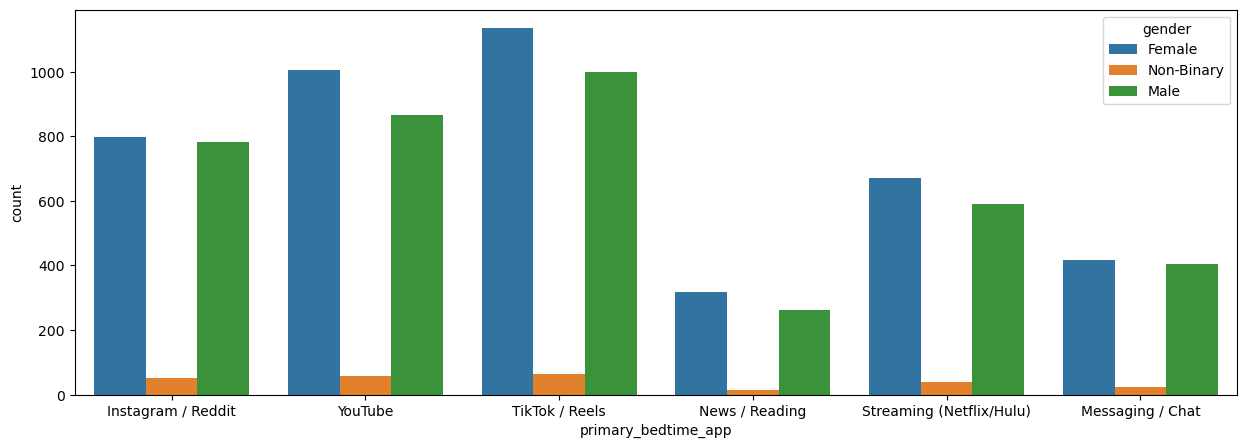

In [7]:
plt.figure(figsize=(15,5))

sns.countplot(data= df, x='primary_bedtime_app', hue = 'gender')

plt.show()

In [8]:
pd.crosstab(df['occupation_type'], df['gender'])

gender,Female,Male,Non-Binary
occupation_type,,,
Corporate 9-to-5,1457,1296,85
Freelance / Creative,465,422,14
Healthcare / Shift Worker,497,474,26
Remote Tech,1080,984,78
Student,848,729,45


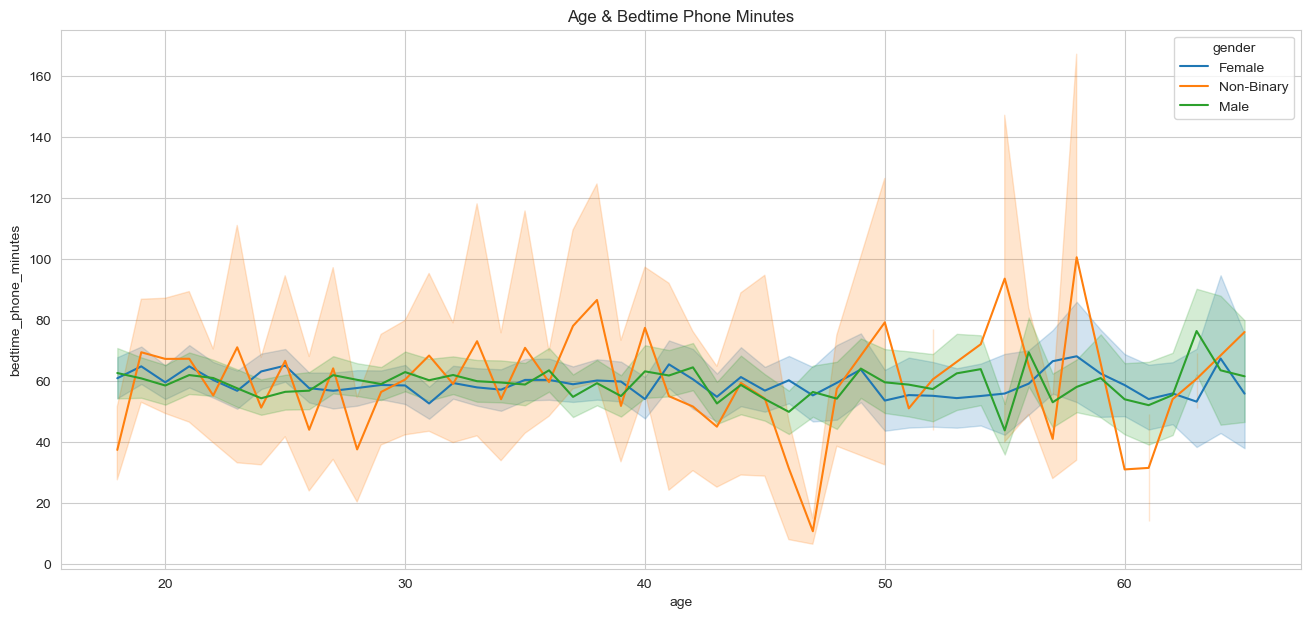

In [9]:
plt.figure(figsize=(16,7))

sns.set_style('whitegrid')
sns.lineplot(data=df , x = 'age', y = 'bedtime_phone_minutes' , hue = 'gender')
plt.title('Age & Bedtime Phone Minutes')

plt.show()

**The average time spent on the phone in bed by female and male groups fluctuates at similar levels across different ages.**

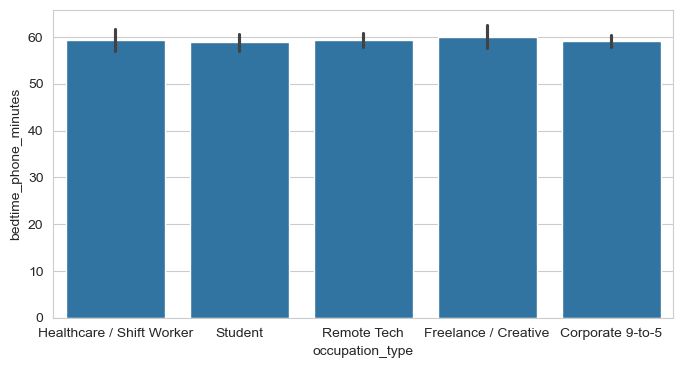

In [10]:
plt.figure(figsize=(8,4))

sns.barplot(data= df, y='bedtime_phone_minutes', x = 'occupation_type')

plt.show()

**There is no clear relationship between age and the time spent on the phone before sleep.**

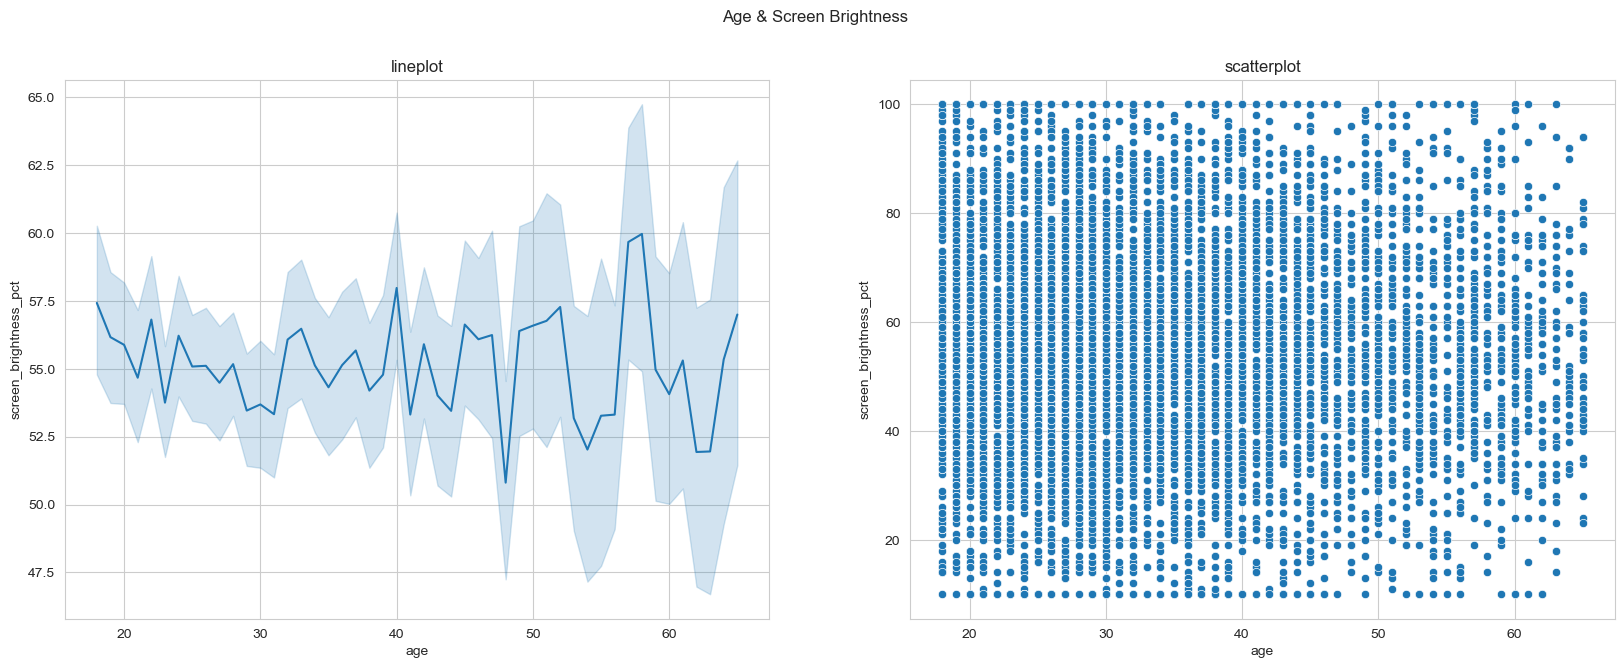

In [11]:
plt.figure(figsize=(20,7))

plt.subplot(1,2,1)
sns.lineplot(data=df, x="age", y="screen_brightness_pct")
plt.title('lineplot')

plt.subplot(1,2,2)
sns.scatterplot(data=df, x="age", y="screen_brightness_pct")
plt.title('scatterplot')

plt.suptitle('Age & Screen Brightness')
                
plt.show()

**There is no clear relationship between age and screen brightness.**

In [12]:
df

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,1,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,2,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,3,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,4,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,5,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,8496,61,Female,Remote Tech,Night Owl,18,Streaming (Netflix/Hulu),61,1,60,74,21.0,5.57,26.5,18.1,3,3.2,Moderate Debt
8496,8497,64,Male,Student,Night Owl,138,TikTok / Reels,58,1,0,58,84.3,3.99,20.4,19.4,7,10.0,Severe Sleep Debt
8497,8498,34,Male,Corporate 9-to-5,Intermediate,56,Streaming (Netflix/Hulu),56,0,94,33,40.6,7.58,17.4,20.7,2,3.7,Mild Deficit
8498,8499,23,Male,Healthcare / Shift Worker,Night Owl,165,TikTok / Reels,72,0,0,52,123.3,3.20,14.2,15.8,7,10.0,Severe Sleep Debt


In [13]:
df.rem_sleep_pct.unique(), df.deep_sleep_pct.unique()

(array([22.2, 21.5, 20.5, 22.4, 22.8, 17.5, 19. , 19.9, 18.5, 16.6, 22.1,
        15.9, 20. , 23.9, 16.7, 19.1, 15.7, 21.2, 19.2, 14.5, 21.3, 19.8,
        20.9, 23.8, 21.6, 21.4, 22.7, 15. , 20.4, 21. , 17.3, 17.1, 23. ,
        18. , 21.1, 23.2, 14.6, 13.3, 20.8, 20.1, 23.4, 18.2, 15.4, 16.1,
        15.8, 20.6, 18.1, 18.4, 21.8, 16.3, 16.5, 23.5, 20.3, 18.7, 22.6,
        24.3, 24.7, 19.5, 16.4, 17.9, 15.5, 22.5, 19.3, 14.9, 16.2, 18.3,
        20.2, 19.6, 22.9, 19.7, 15.6, 17.8, 18.8, 18.9, 18.6, 21.9, 19.4,
        17. , 14.1, 20.7, 21.7, 17.4, 16.9, 17.6, 17.2, 23.7, 14.7, 13.9,
        22.3, 17.7, 16. , 16.8, 13.7, 25.3, 15.2, 23.3, 13.6, 14.8, 23.6,
        14.2, 14. , 15.1, 25.2, 22. , 26. , 25. , 24.4, 11.4, 10.6, 24.1,
        24. , 14.3, 12.6, 12.9, 13.5, 23.1, 13.4, 12.2, 13. , 15.3, 13.2,
        24.5, 11.9, 12.1, 12.3, 14.4, 26.1, 25.9, 24.8, 25.8, 10.7, 24.6,
        26.4, 24.2, 12.5, 12.8, 27. , 11.7,  9.8, 12.4, 13.8, 11.8, 25.5,
        25.7, 26.2, 25.6, 10.3, 10. , 

In [14]:
df['rem_sleep_minutes'] = df['total_sleep_hours'] * 60 * df['rem_sleep_pct'] / 100
df['deep_sleep_minutes'] = df['total_sleep_hours'] * 60 * df['deep_sleep_pct'] / 100

**Deep and REM sleep are given as percentages, so we convert them into minutes for a clearer analysis.**

In [15]:
df

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category,rem_sleep_minutes,deep_sleep_minutes
0,1,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt,42.6240,45.1200
1,2,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt,52.3740,43.8480
2,3,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt,39.3600,34.7520
3,4,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit,93.9456,90.5904
4,5,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt,62.6544,66.2268
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,8496,61,Female,Remote Tech,Night Owl,18,Streaming (Netflix/Hulu),61,1,60,74,21.0,5.57,26.5,18.1,3,3.2,Moderate Debt,60.4902,88.5630
8496,8497,64,Male,Student,Night Owl,138,TikTok / Reels,58,1,0,58,84.3,3.99,20.4,19.4,7,10.0,Severe Sleep Debt,46.4436,48.8376
8497,8498,34,Male,Corporate 9-to-5,Intermediate,56,Streaming (Netflix/Hulu),56,0,94,33,40.6,7.58,17.4,20.7,2,3.7,Mild Deficit,94.1436,79.1352
8498,8499,23,Male,Healthcare / Shift Worker,Night Owl,165,TikTok / Reels,72,0,0,52,123.3,3.20,14.2,15.8,7,10.0,Severe Sleep Debt,30.3360,27.2640


In [16]:
df['deep_sleep_minutes'] = df['deep_sleep_minutes'].round(1)
df['rem_sleep_minutes'] = df['rem_sleep_minutes'].round(1) 

In [17]:
df

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category,rem_sleep_minutes,deep_sleep_minutes
0,1,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt,42.6,45.1
1,2,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt,52.4,43.8
2,3,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt,39.4,34.8
3,4,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit,93.9,90.6
4,5,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt,62.7,66.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,8496,61,Female,Remote Tech,Night Owl,18,Streaming (Netflix/Hulu),61,1,60,74,21.0,5.57,26.5,18.1,3,3.2,Moderate Debt,60.5,88.6
8496,8497,64,Male,Student,Night Owl,138,TikTok / Reels,58,1,0,58,84.3,3.99,20.4,19.4,7,10.0,Severe Sleep Debt,46.4,48.8
8497,8498,34,Male,Corporate 9-to-5,Intermediate,56,Streaming (Netflix/Hulu),56,0,94,33,40.6,7.58,17.4,20.7,2,3.7,Mild Deficit,94.1,79.1
8498,8499,23,Male,Healthcare / Shift Worker,Night Owl,165,TikTok / Reels,72,0,0,52,123.3,3.20,14.2,15.8,7,10.0,Severe Sleep Debt,30.3,27.3


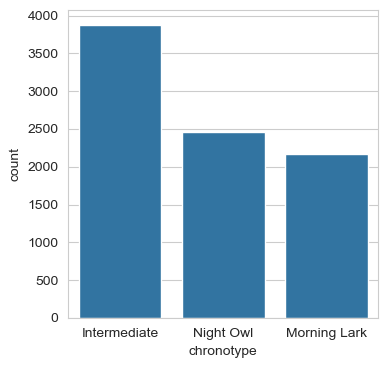

In [18]:
plt.figure(figsize=(4,4))
sns.countplot(data=df, x = 'chronotype')
plt.show()

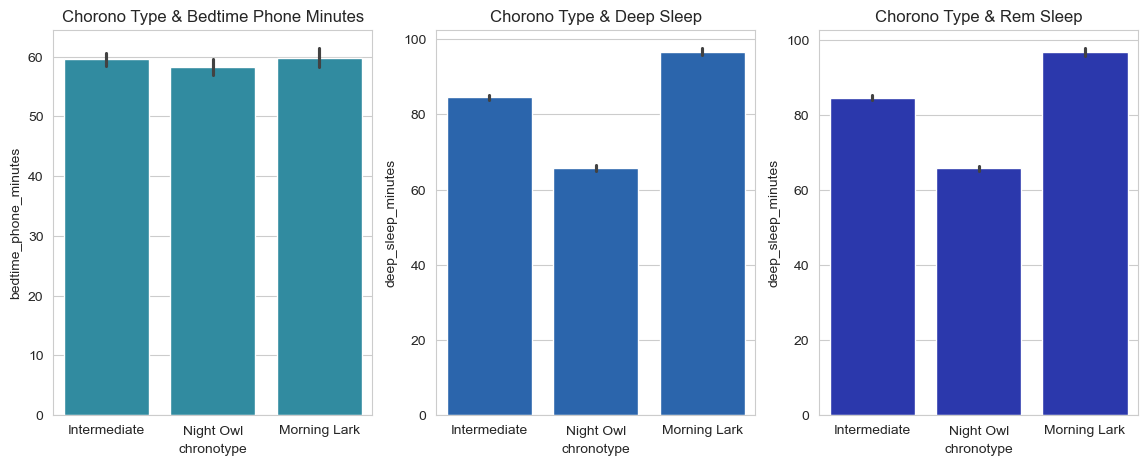

In [19]:
plt.figure(figsize=(14,5))

plt.subplot(1,3,1)
sns.barplot(data=df, x= 'chronotype', y='bedtime_phone_minutes', color= '#1e97b3')
plt.title('Chorono Type & Bedtime Phone Minutes')

plt.subplot(1,3,2)
sns.barplot(data=df, x= 'chronotype', y='deep_sleep_minutes', color= '#1563c2')
plt.title('Chorono Type & Deep Sleep')

plt.subplot(1,3,3)
sns.barplot(data=df, x= 'chronotype', y='deep_sleep_minutes', color= '#1527c2')
plt.title('Chorono Type & Rem Sleep')

plt.show()

**There is no significant difference in bedtime phone use between chronotypes. Deep and REM sleep durations are higher in the Morning Lark chronotype.**

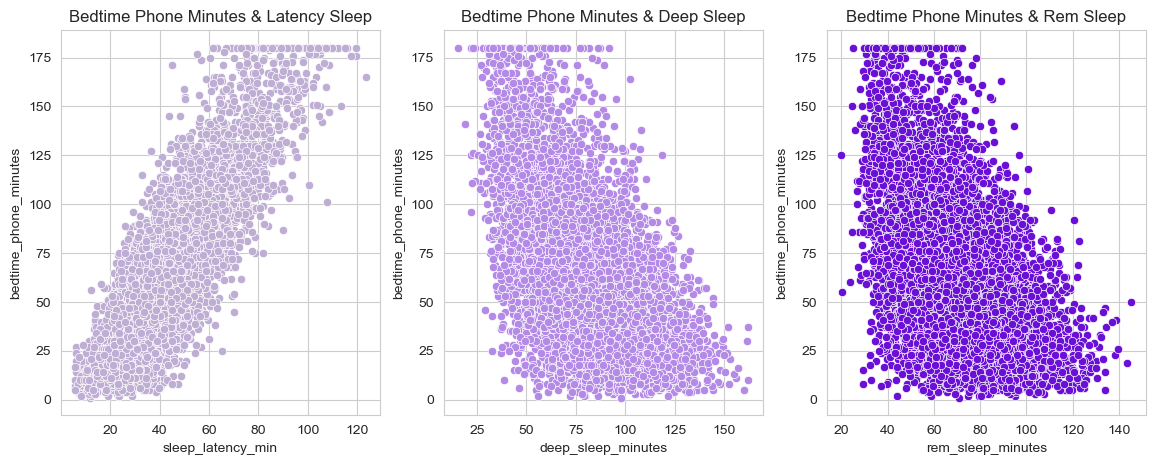

In [20]:
plt.figure(figsize=(14,5))

plt.subplot(1,3,1)
sns.scatterplot(data=df, x= 'sleep_latency_min', y='bedtime_phone_minutes', color= '#bfaed4')
plt.title('Bedtime Phone Minutes & Latency Sleep')

plt.subplot(1,3,2)
sns.scatterplot(data=df, x= 'deep_sleep_minutes', y='bedtime_phone_minutes', color= '#b38ae6')
plt.title('Bedtime Phone Minutes & Deep Sleep')

plt.subplot(1,3,3)
sns.scatterplot(data=df, x= 'rem_sleep_minutes', y='bedtime_phone_minutes', color= '#690fd6')
plt.title('Bedtime Phone Minutes & Rem Sleep')

plt.show()


- **There is a strong positive relationship between bedtime phone use and sleep latency.**
- **As bedtime phone use increases, deep sleep duration decreases.**
- **There is a negative relationship between REM sleep duration and bedtime phone use. However, this relationship appears weaker than the relationship with deep sleep.**

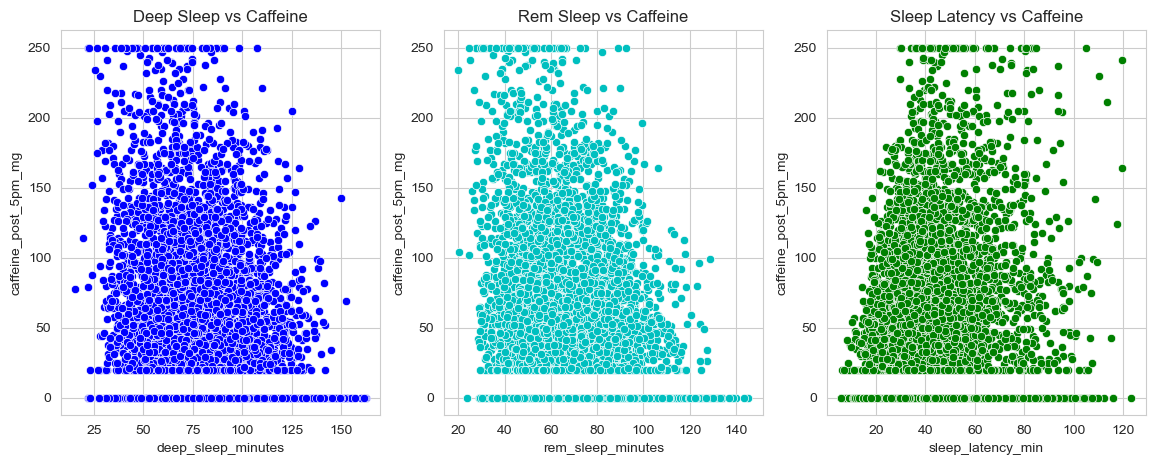

In [21]:
plt.figure(figsize=(14,5))

plt.subplot(1,3,1)
sns.scatterplot(data=df , x = 'deep_sleep_minutes', y= 'caffeine_post_5pm_mg' ,color ='b' )
plt.title('Deep Sleep vs Caffeine')

plt.subplot(1,3,2)
sns.scatterplot(data=df , x = 'rem_sleep_minutes', y= 'caffeine_post_5pm_mg', color= 'c')
plt.title('Rem Sleep vs Caffeine')

plt.subplot(1,3,3)
sns.scatterplot(data=df , x = 'sleep_latency_min', y= 'caffeine_post_5pm_mg', color = 'g')
plt.title('Sleep Latency vs Caffeine')

plt.show()

- **There is no clear relationship between caffeine and deep sleep. However, there is a weak negative relationship.**
- **There is no clear relationship between caffeine and REM sleep. A weak negative relationship can be observed.**
- **There is no clear linear relationship between caffeine and sleep latency.**

In [22]:
df

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category,rem_sleep_minutes,deep_sleep_minutes
0,1,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt,42.6,45.1
1,2,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt,52.4,43.8
2,3,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt,39.4,34.8
3,4,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit,93.9,90.6
4,5,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt,62.7,66.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,8496,61,Female,Remote Tech,Night Owl,18,Streaming (Netflix/Hulu),61,1,60,74,21.0,5.57,26.5,18.1,3,3.2,Moderate Debt,60.5,88.6
8496,8497,64,Male,Student,Night Owl,138,TikTok / Reels,58,1,0,58,84.3,3.99,20.4,19.4,7,10.0,Severe Sleep Debt,46.4,48.8
8497,8498,34,Male,Corporate 9-to-5,Intermediate,56,Streaming (Netflix/Hulu),56,0,94,33,40.6,7.58,17.4,20.7,2,3.7,Mild Deficit,94.1,79.1
8498,8499,23,Male,Healthcare / Shift Worker,Night Owl,165,TikTok / Reels,72,0,0,52,123.3,3.20,14.2,15.8,7,10.0,Severe Sleep Debt,30.3,27.3


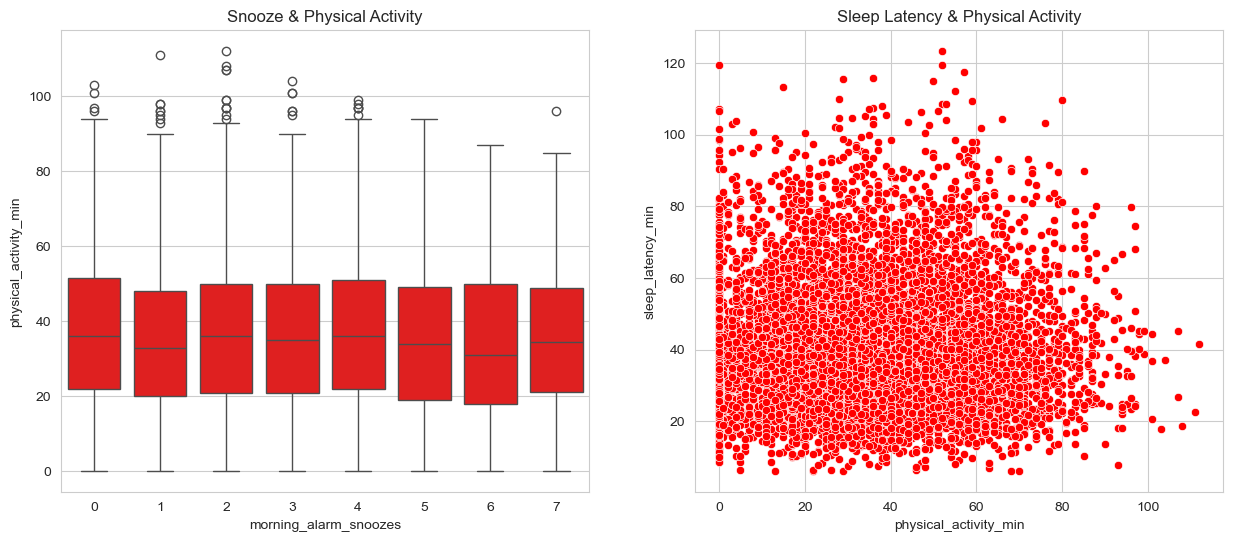

In [23]:
plt.figure(figsize=(15,6))
plt.subplot(1,2,1)
sns.boxplot(data=df, x= 'morning_alarm_snoozes', y = 'physical_activity_min',  color= 'r')
plt.title('Snooze & Physical Activity')

plt.subplot(1,2,2)
sns.scatterplot(data=df, y= 'sleep_latency_min', x = 'physical_activity_min',  color= 'r')
plt.title('Sleep Latency & Physical Activity')

plt.show()

- **There is no clear relationship between physical activity and the number of alarm snoozes.**
- **There is no direct relationship between sleep latency and physical activity duration.**

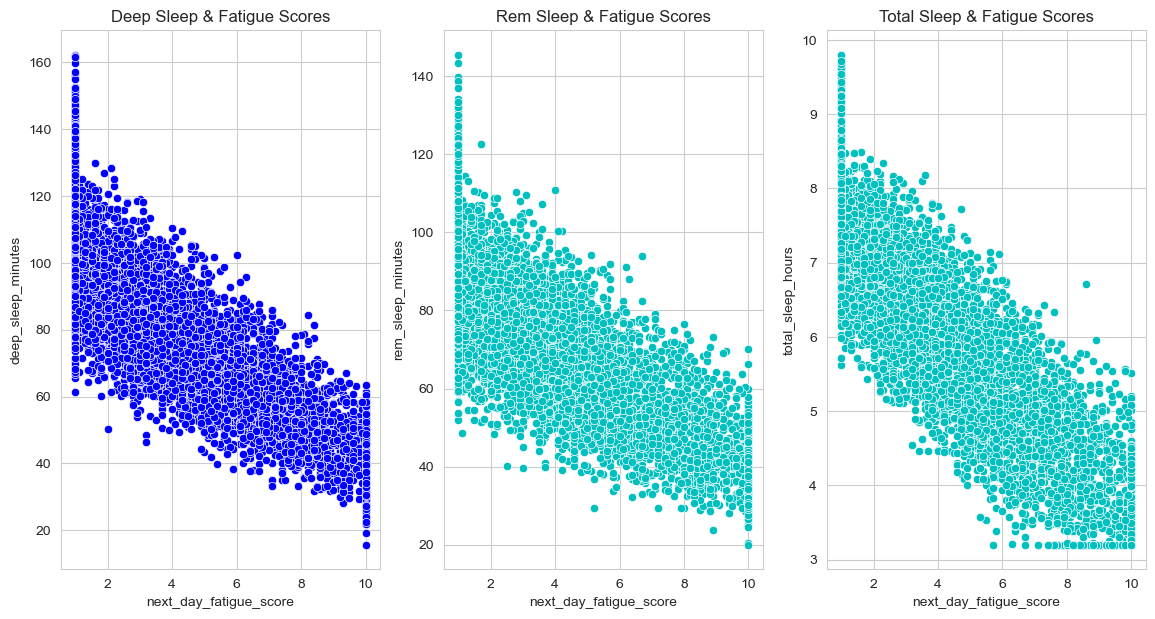

In [24]:
plt.figure(figsize=(14,7))

plt.subplot(1,3,1)
sns.scatterplot(data=df, y= 'deep_sleep_minutes' , x= 'next_day_fatigue_score', color='b' )
plt.title('Deep Sleep & Fatigue Scores')

plt.subplot(1,3,2)
sns.scatterplot(data=df, x = 'next_day_fatigue_score', y= 'rem_sleep_minutes', color= 'c')
plt.title('Rem Sleep & Fatigue Scores')

plt.subplot(1,3,3)
sns.scatterplot(data=df, x = 'next_day_fatigue_score', y= 'total_sleep_hours', color= 'c')
plt.title('Total Sleep & Fatigue Scores')

plt.show()

**As deep sleep, REM sleep, and total sleep duration decrease, the next-day fatigue score increases.**

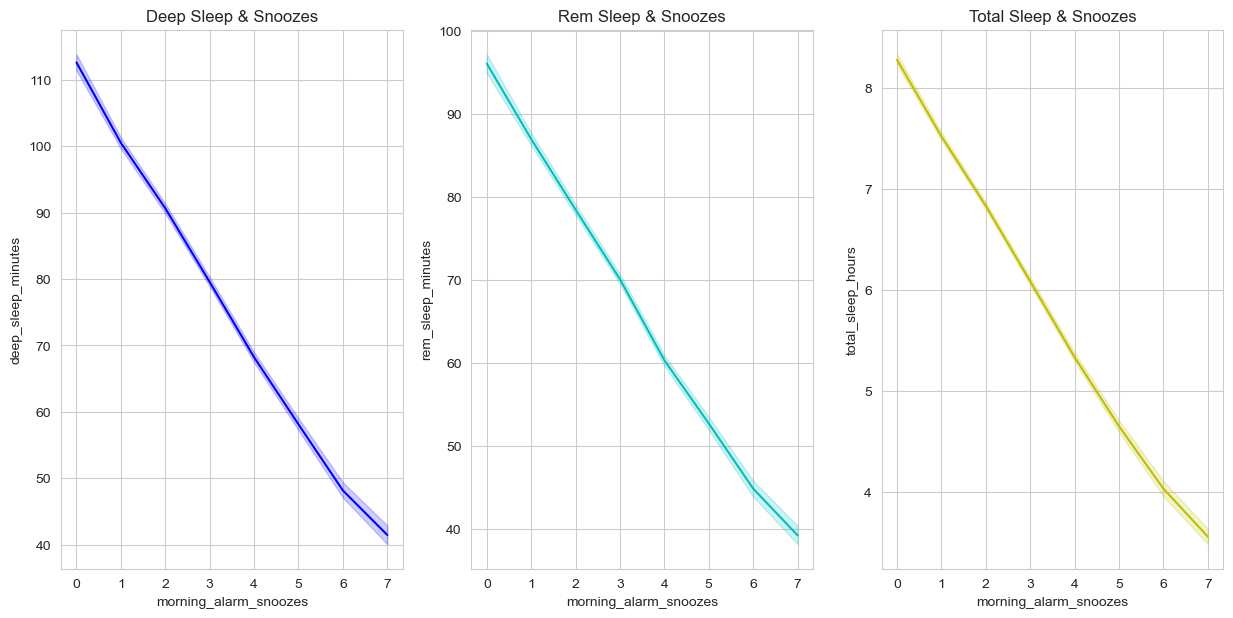

In [25]:
plt.figure(figsize=(15,7))

plt.subplot(1,3,1)
sns.lineplot(data=df, y= 'deep_sleep_minutes' , x= 'morning_alarm_snoozes', color='b' )
plt.title('Deep Sleep & Snoozes')

plt.subplot(1,3,2)
sns.lineplot(data=df, x = 'morning_alarm_snoozes', y= 'rem_sleep_minutes', color= 'c')
plt.title('Rem Sleep & Snoozes')

plt.subplot(1,3,3)
sns.lineplot(data=df, x = 'morning_alarm_snoozes', y= 'total_sleep_hours', color= 'y')
plt.title('Total Sleep & Snoozes') 

plt.show()

**As total sleep, deep sleep, and REM sleep duration decrease, the frequency of alarm snoozing increases.**

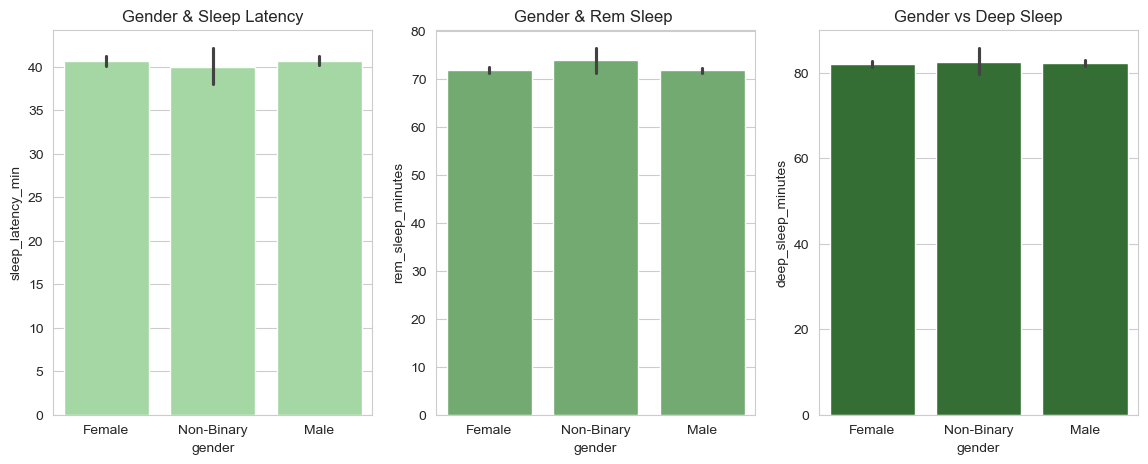

In [26]:
plt.figure(figsize=(14,5))

plt.subplot(1,3,1)
sns.barplot(data=df , x = 'gender', y= 'sleep_latency_min' ,color ='#9ce09b' )
plt.title('Gender & Sleep Latency')

plt.subplot(1,3,2)
sns.barplot(data=df , x = 'gender', y= 'rem_sleep_minutes', color= '#69b368')
plt.title('Gender & Rem Sleep ')

plt.subplot(1,3,3)
sns.barplot(data=df , x = 'gender' , y= 'deep_sleep_minutes', color = '#2b782a')
plt.title('Gender vs Deep Sleep')

plt.show()

In [27]:
df

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category,rem_sleep_minutes,deep_sleep_minutes
0,1,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt,42.6,45.1
1,2,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt,52.4,43.8
2,3,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt,39.4,34.8
3,4,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit,93.9,90.6
4,5,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt,62.7,66.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,8496,61,Female,Remote Tech,Night Owl,18,Streaming (Netflix/Hulu),61,1,60,74,21.0,5.57,26.5,18.1,3,3.2,Moderate Debt,60.5,88.6
8496,8497,64,Male,Student,Night Owl,138,TikTok / Reels,58,1,0,58,84.3,3.99,20.4,19.4,7,10.0,Severe Sleep Debt,46.4,48.8
8497,8498,34,Male,Corporate 9-to-5,Intermediate,56,Streaming (Netflix/Hulu),56,0,94,33,40.6,7.58,17.4,20.7,2,3.7,Mild Deficit,94.1,79.1
8498,8499,23,Male,Healthcare / Shift Worker,Night Owl,165,TikTok / Reels,72,0,0,52,123.3,3.20,14.2,15.8,7,10.0,Severe Sleep Debt,30.3,27.3


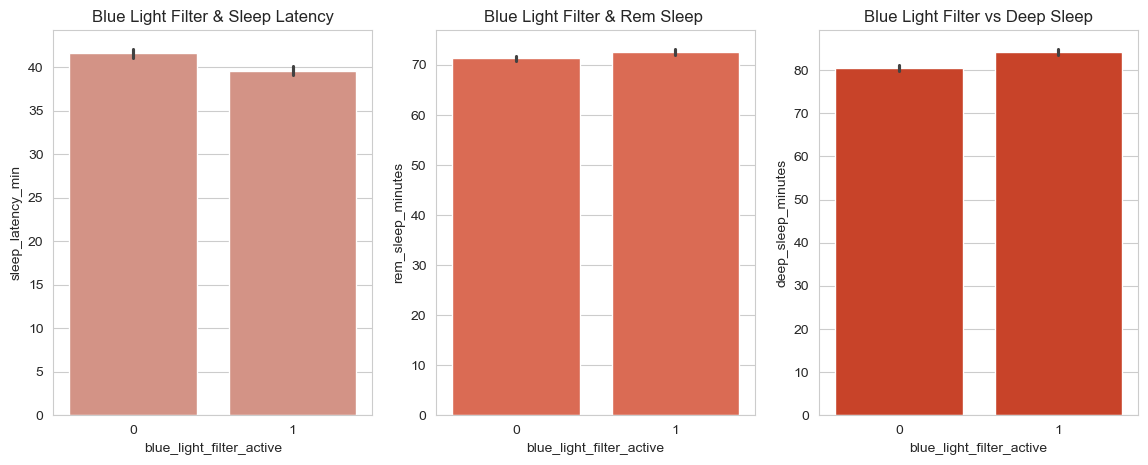

In [28]:
plt.figure(figsize=(14,5))

plt.subplot(1,3,1)
sns.barplot(data=df , x = 'blue_light_filter_active', y= 'sleep_latency_min' ,color ='#e08a79' )
plt.title('Blue Light Filter & Sleep Latency')

plt.subplot(1,3,2)
sns.barplot(data=df , x = 'blue_light_filter_active', y= 'rem_sleep_minutes', color= '#f05c3e')
plt.title('Blue Light Filter & Rem Sleep ')

plt.subplot(1,3,3)
sns.barplot(data=df , x = 'blue_light_filter_active' , y= 'deep_sleep_minutes', color = '#e3310e')
plt.title('Blue Light Filter vs Deep Sleep')

plt.show()

**There is no clear difference in sleep latency, REM sleep, and deep sleep duration based on blue light filter usage.**

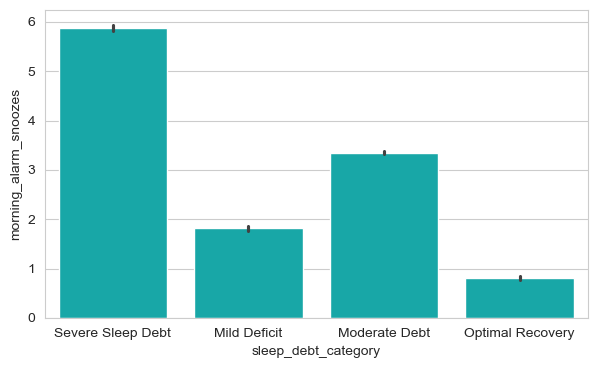

In [29]:
plt.figure(figsize=(7,4))
sns.barplot(data = df, x = 'sleep_debt_category',  y= 'morning_alarm_snoozes', color= 'c')
plt.show()

**As sleep debt increases, the number of alarm snoozes also increases.**

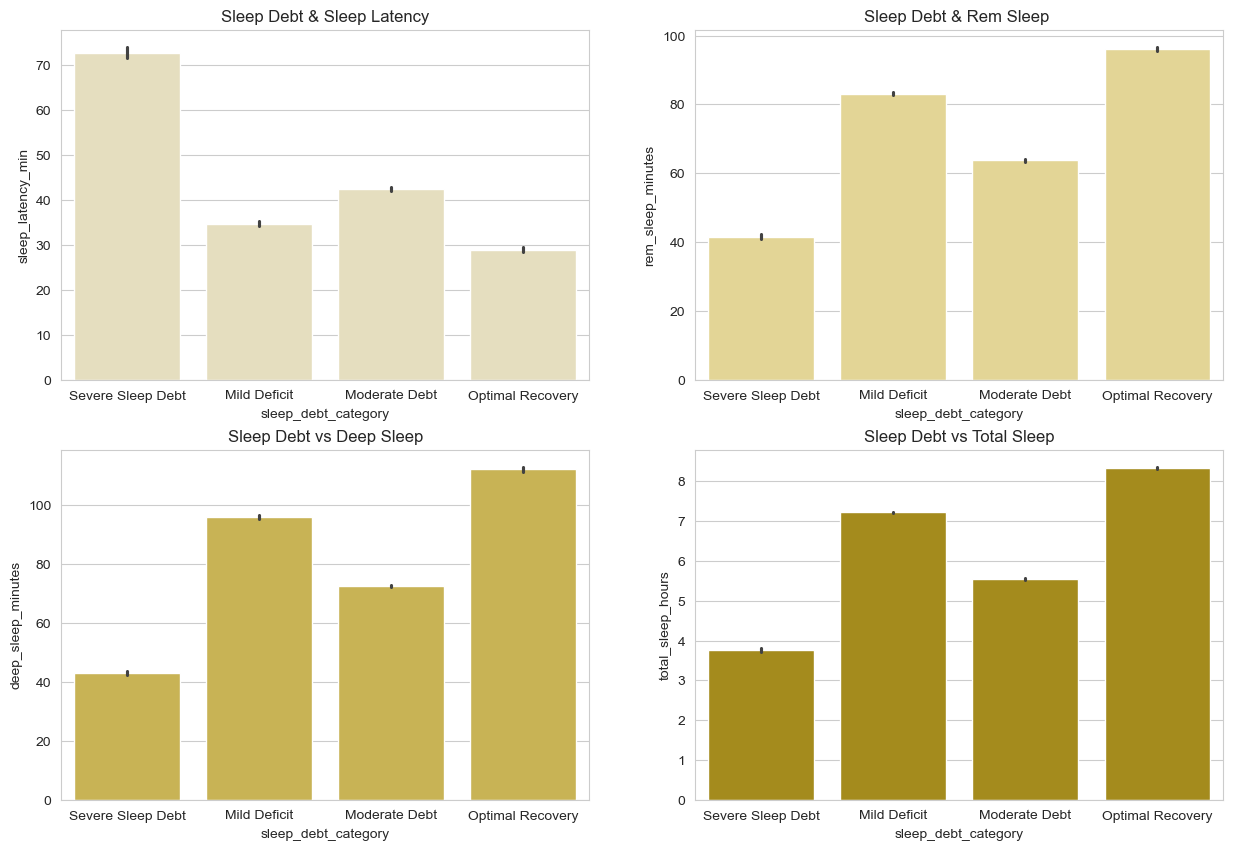

In [30]:
plt.figure(figsize=(15,10))

plt.subplot(2,2,1)
sns.barplot(data=df , x = 'sleep_debt_category', y= 'sleep_latency_min' ,color ='#ebe2b9' )
plt.title('Sleep Debt & Sleep Latency')

plt.subplot(2,2,2)
sns.barplot(data=df , x = 'sleep_debt_category', y= 'rem_sleep_minutes', color= '#f0dd89')
plt.title('Sleep Debt & Rem Sleep ')

plt.subplot(2,2,3)
sns.barplot(data=df , x = 'sleep_debt_category' , y= 'deep_sleep_minutes', color = '#dbbf42')
plt.title('Sleep Debt vs Deep Sleep')

plt.subplot(2,2,4)
sns.barplot(data=df , x = 'sleep_debt_category' , y= 'total_sleep_hours', color = '#ba9907')
plt.title('Sleep Debt vs Total Sleep')
plt.show()

**As sleep debt increases, total sleep, deep sleep, and REM sleep duration decrease. Groups with higher sleep debt also have longer sleep latency.**

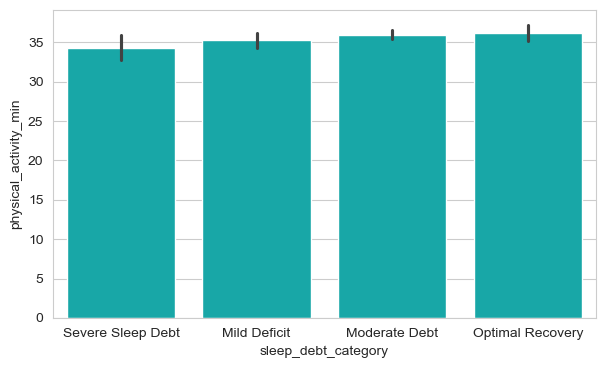

In [31]:
plt.figure(figsize=(7,4))
sns.barplot(data=df, x='sleep_debt_category', y= 'physical_activity_min', color='c')
plt.show()

**There is no clear relationship between sleep debt categories and physical activity duration.**

In [34]:
df.drop(['deep_sleep_pct', 'rem_sleep_pct'], axis =1,inplace =True)

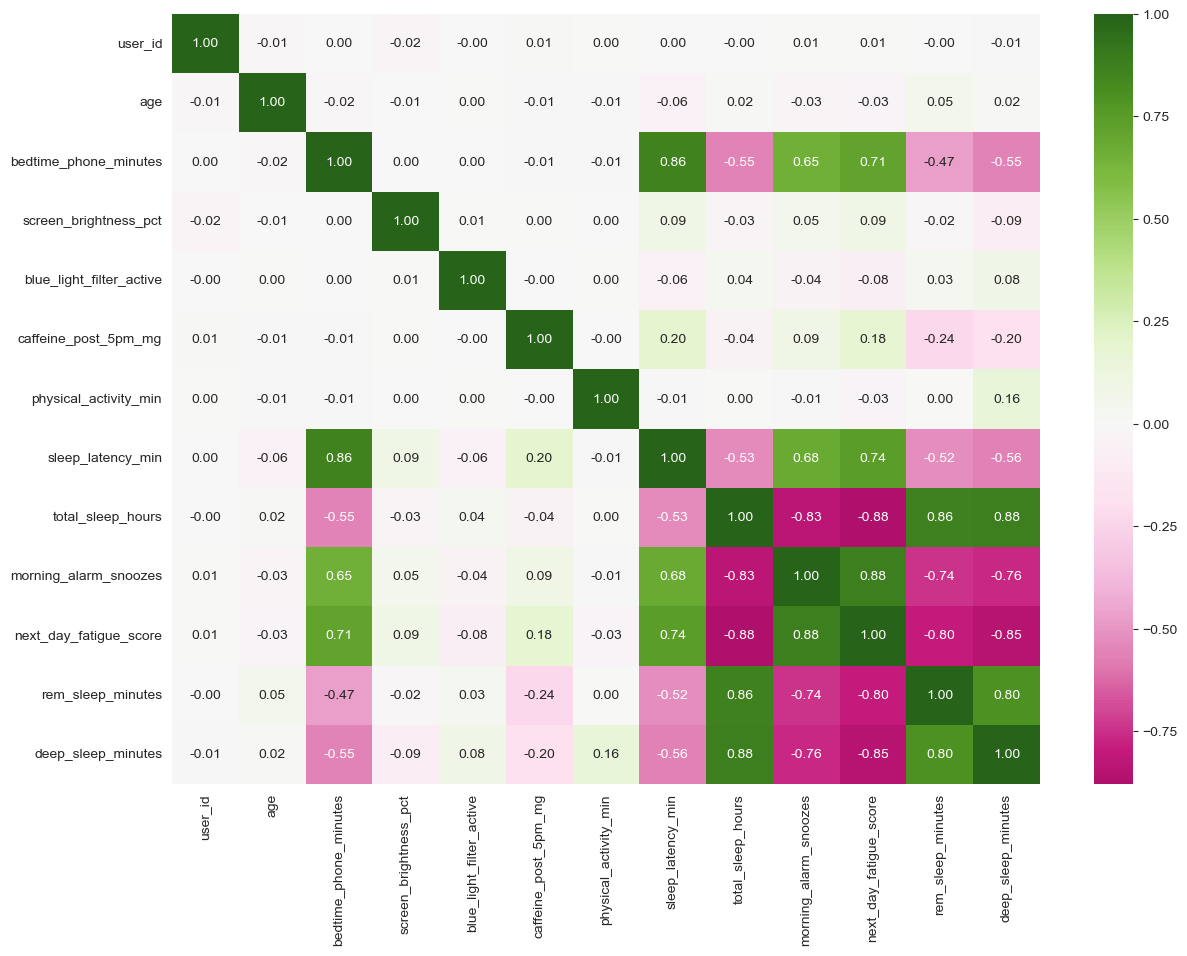

In [35]:
plt.figure(figsize=(14,10))
sns.heatmap(df.corr(numeric_only= True), annot=True, fmt=".2f", cmap="PiYG" ,center=0)

plt.show()

General Findings
- The correlation analysis largely supports the observations made from the previous visualizations.
- A strong positive correlation is observed between bedtime phone use and sleep latency.
- As bedtime phone use increases, total sleep, deep sleep, and REM sleep duration tend to decrease.
- Lower total sleep duration is associated with more frequent alarm snoozing and higher next-day fatigue scores.
- Higher sleep latency is associated with lower total sleep duration, more frequent alarm snoozing, and higher next-day fatigue scores.
- A very strong positive correlation is observed between alarm snooze frequency and next-day fatigue score.
- The correlations between caffeine consumption and sleep-related variables are relatively weak.
- No clear linear relationship is observed between screen brightness, blue-light filter usage, physical activity, and the main sleep-related variables.
- Overall, bedtime phone use, sleep latency, total sleep duration, and alarm snooze frequency show the most prominent relationships in the dataset.

## Preparing the Dataset for Machine Learning

In [62]:
from sklearn .preprocessing import OrdinalEncoder

In [46]:
df = pd.get_dummies(df,columns= ['gender','occupation_type','chronotype','primary_bedtime_app'], drop_first =True)

In [47]:
df

,user_id,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,morning_alarm_snoozes,...,occupation_type_Healthcare / Shift Worker,occupation_type_Remote Tech,occupation_type_Student,chronotype_Morning Lark,chronotype_Night Owl,primary_bedtime_app_Messaging / Chat,primary_bedtime_app_News / Reading,primary_bedtime_app_Streaming (Netflix/Hulu),primary_bedtime_app_TikTok / Reels,primary_bedtime_app_YouTube
0,1,29,179,54,1,0,21,84.4,3.20,7,...,True,False,False,False,False,False,False,False,False,False
1,2,58,163,76,1,92,72,86.7,4.06,7,...,False,False,True,False,False,False,False,False,False,True
2,3,41,100,59,0,45,23,70.5,3.20,7,...,True,False,False,False,True,False,False,False,True,False
3,4,36,34,52,0,97,49,38.1,6.99,1,...,False,True,False,False,False,False,False,False,False,True
4,5,23,27,82,1,0,38,32.3,4.58,4,...,True,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,8496,61,18,61,1,60,74,21.0,5.57,3,...,False,True,False,False,True,False,False,True,False,False
8496,8497,64,138,58,1,0,58,84.3,3.99,7,...,False,False,True,False,True,False,False,False,True,False
8497,8498,34,56,56,0,94,33,40.6,7.58,2,...,False,False,False,False,False,False,False,True,False,False
8498,8499,23,165,72,0,0,52,123.3,3.20,7,...,True,False,False,False,True,False,False,False,True,False


In [48]:
df.sleep_debt_category.unique()

array(['Severe Sleep Debt', 'Mild Deficit', 'Moderate Debt',
       'Optimal Recovery'], dtype=object)

In [51]:
category = ['Severe Sleep Debt', 'Moderate Debt', 'Mild Deficit', 'Optimal Recovery']

In [54]:
encode = OrdinalEncoder(categories=[category])
df['sleep_debt_category']= encode.fit_transform(df[['sleep_debt_category']])

In [55]:
df

,user_id,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,morning_alarm_snoozes,...,occupation_type_Healthcare / Shift Worker,occupation_type_Remote Tech,occupation_type_Student,chronotype_Morning Lark,chronotype_Night Owl,primary_bedtime_app_Messaging / Chat,primary_bedtime_app_News / Reading,primary_bedtime_app_Streaming (Netflix/Hulu),primary_bedtime_app_TikTok / Reels,primary_bedtime_app_YouTube
0,1,29,179,54,1,0,21,84.4,3.20,7,...,True,False,False,False,False,False,False,False,False,False
1,2,58,163,76,1,92,72,86.7,4.06,7,...,False,False,True,False,False,False,False,False,False,True
2,3,41,100,59,0,45,23,70.5,3.20,7,...,True,False,False,False,True,False,False,False,True,False
3,4,36,34,52,0,97,49,38.1,6.99,1,...,False,True,False,False,False,False,False,False,False,True
4,5,23,27,82,1,0,38,32.3,4.58,4,...,True,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,8496,61,18,61,1,60,74,21.0,5.57,3,...,False,True,False,False,True,False,False,True,False,False
8496,8497,64,138,58,1,0,58,84.3,3.99,7,...,False,False,True,False,True,False,False,False,True,False
8497,8498,34,56,56,0,94,33,40.6,7.58,2,...,False,False,False,False,False,False,False,True,False,False
8498,8499,23,165,72,0,0,52,123.3,3.20,7,...,True,False,False,False,True,False,False,False,True,False


In [56]:
df['sleep_debt_category']

0       0.0
1       0.0
2       0.0
3       2.0
4       1.0
       ... 
8495    1.0
8496    0.0
8497    2.0
8498    0.0
8499    1.0
Name: sleep_debt_category, Length: 8500, dtype: float64

In [58]:
df['sleep_debt_category'] = df['sleep_debt_category'].astype(int)

In [59]:
df['sleep_debt_category']

0       0
1       0
2       0
3       2
4       1
       ..
8495    1
8496    0
8497    2
8498    0
8499    1
Name: sleep_debt_category, Length: 8500, dtype: int64

In [60]:
pd.set_option('display.max_columns', None)

In [61]:
df.head()

,user_id,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category,rem_sleep_minutes,deep_sleep_minutes,gender_Male,gender_Non-Binary,occupation_type_Freelance / Creative,occupation_type_Healthcare / Shift Worker,occupation_type_Remote Tech,occupation_type_Student,chronotype_Morning Lark,chronotype_Night Owl,primary_bedtime_app_Messaging / Chat,primary_bedtime_app_News / Reading,primary_bedtime_app_Streaming (Netflix/Hulu),primary_bedtime_app_TikTok / Reels,primary_bedtime_app_YouTube
0,1,29,179,54,1,0,21,84.4,3.20,7,10.0,0,42.6,45.1,False,False,False,True,False,False,False,False,False,False,False,False,False
1,2,58,163,76,1,92,72,86.7,4.06,7,10.0,0,52.4,43.8,False,False,False,False,False,True,False,False,False,False,False,False,True
2,3,41,100,59,0,45,23,70.5,3.20,7,10.0,0,39.4,34.8,False,False,False,True,False,False,False,True,False,False,False,True,False
3,4,36,34,52,0,97,49,38.1,6.99,1,1.7,2,93.9,90.6,False,True,False,False,True,False,False,False,False,False,False,False,True
4,5,23,27,82,1,0,38,32.3,4.58,4,5.3,1,62.7,66.2,False,False,False,True,False,False,False,False,False,False,False,True,False
